# Integrated evaluator: visibility selection rules

Compare **performance-based**, **similarity-based**, and **dissimilarity-based** selection on three primary outcomes: breakthrough discovery, pairwise solution diversity (dispersion), and adopted solution fitness (orientation). Each outcome is plotted separately and in one unified three-panel figure. Generative potential is available as an optional fourth outcome.

All three scripts use 100 eligible senders (`visibility_extent = 1.0`) and expose exactly 10 sender entries per recipient at every 10-period visibility event (effective per-recipient extent `v = 0.1`). Selection strength `s` determines how many of the 10 entries are rule-selected (0, 2, 4, 6, 8, or 10). At `s = 0`, all 10 sender identities are randomly selected once per crowd reset and remain fixed across recipients and events; this is limited visibility, not search-apart. For `s > 0`, performance selection uses a common fitness ranking and fills remaining slots from a fixed random ordering, skipping rule-selected senders; similarity and dissimilarity reserve shared fixed random senders and select the other entries using recipient-specific Hamming distances. Sender solutions are refreshed at every event.

All outcomes concern the recipient crowd. Each point equally weights the nine K-level means (`K = 9, ..., 17`). The zero-strength conditions are equivalent in experimental design, not necessarily numerically identical across independent simulations. Preserve all three observed values without pooling or forcing a common intercept. Lower breakthrough rank is better. Adopted fitness and generative potential can be undefined when no adoption occurs.

Source configurations: `Visibility_rank_selection(8).py` (600 landscapes × 10 resets per K), `Visibility_similarity_selection(6).py` and `Visibility_dissimilarity_selection(7).py` (400 landscapes × 5 resets per K each). These replication counts document the supplied scripts; pickle files do not themselves verify the counts or run version. Only aggregated means are saved, so no run-level confidence intervals or significance tests are inferred.

In [2]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np

# Use the same visual conventions as the three source evaluators.
legend_properties = {'weight': 'bold', 'size': 11}


def format_axis(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.4)
    ax.tick_params(axis='both', labelsize=11)
    ax.set_axisbelow(True)
    return ax


def safe_nanmean(values, axis=None):
    # Retain NaN when adoption quality is undefined for all K values.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)

## 1. Configuration

Set `base_folder` to the parent of the three result directories. The default folders are retained from the original integrated evaluator. The performance-based filename prefix is updated to the fixed-random version; dissimilarity retains the script's `novelty` prefix. No fallback to older prefixes is used, to avoid accidentally mixing experimental designs. Set `include_generative_potential = True` to add the optional fourth outcome to the separate and combined plots.

In [3]:
# Common simulation settings (matching the three running scripts).
N = 18
K_list = list(range(9, N))  # K = 9, ..., 17
agent_num = 100
knowledge_breadth = 12
search_iteration = 300
visibility_extent = 1.0  # Eligible sender pool, not realized exposure per recipient.
recommendation_num = 10
effective_visibility_extent = recommendation_num / agent_num
visibility_interval = 10
selection_strength_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
x = np.asarray(selection_strength_list, dtype=float)

# Parent of Rank_based / Similarity_based / Dissimilarity_based result folders.
base_folder = Path('/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2')

# Matching the existing simulation-output naming conventions exactly.
selection_rules = {
    'Performance-based': {
        'folder': base_folder / 'Rank_based',
        'prefix': 'visibility_rank_selection_fixed_random_strength',
        'landscape_iteration': 600,
        'solver_reset_num': 10,
        'marker': 'o',
        'linestyle': '-',
    },
    'Similarity-based': {
        'folder': base_folder / 'Similarity_based',
        'prefix': 'visibility_similarity_selection_strength',
        'landscape_iteration': 400,
        'solver_reset_num': 5,
        'marker': 's',
        'linestyle': '--',
    },
    'Dissimilarity-based': {
        'folder': base_folder / 'Dissimilarity_based',
        'prefix': 'visibility_novelty_selection_strength',
        'landscape_iteration': 400,
        'solver_reset_num': 5,
        'marker': '^',
        'linestyle': '-',
    },
}

# Preserve the three primary outcomes; optional generative-potential comparison.
outcomes = {
    'breakthrough_rank': {
        'ylabel': 'Best solution rank (lower is better)',
        'title': 'Breakthrough discovery',
        'filename': 'Breakthrough_across_selection_strength.png',
    },
    'pairwise_diversity': {
        'ylabel': 'Pairwise solution diversity',
        'title': 'Dispersion',
        'filename': 'Pairwise_diversity_across_selection_strength.png',
    },
    'adopted_solution_fitness': {
        'ylabel': 'Adopted solution fitness',
        'title': 'Orientation',
        'filename': 'Adopted_solution_quality_across_selection_strength.png',
    },
}

include_generative_potential = False
if include_generative_potential:
    outcomes['generative_potential'] = {
        'ylabel': 'Generative potential',
        'title': 'Generative potential',
        'filename': 'Generative_potential_across_selection_strength.png',
    }

save_figures = True
figure_folder = base_folder / 'Integrated_selection_figures'

print('Selection strengths:', selection_strength_list)
print('Fixed number of recommendations:', recommendation_num)
for rule, settings in selection_rules.items():
    print(f'{rule:20s}: {settings["folder"]} | '
          f'{settings["landscape_iteration"]} landscapes × {settings["solver_reset_num"]} resets per K')

Selection strengths: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
Fixed number of recommendations: 10
Performance-based   : /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Rank_based | 600 landscapes × 10 resets per K
Similarity-based    : /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Similarity_based | 400 landscapes × 5 resets per K
Dissimilarity-based : /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Dissimilarity_based | 400 landscapes × 5 resets per K


## 2. Load and validate outcomes

Read the underlying pickles directly rather than combining screenshots or requiring the three sub-evaluators to run first. Each plotted outcome has nine pre-averaged values per selection strength. With the three main outcomes, 54 files are required (3 rules × 6 strengths × 3 outcomes); the optional generative-potential comparison requires 18 more. Missing, malformed, or wrongly shaped files raise an informative error. NaN is retained for undefined adoption-related measures. The scripts save seven families in total, but only those selected for plotting are loaded here.

In [4]:
def result_file(settings, strength, dv):
    name = (
        f'{settings["prefix"]}_{strength}'
        f'_recommendation_num_{recommendation_num}_interval_{visibility_interval}'
        f'_{dv}_across_K_size_{agent_num}'
    )
    return settings['folder'] / name


def load_selection_results():
    results = {}
    problems = []
    for rule, settings in selection_rules.items():
        results[rule] = {}
        for dv in outcomes:
            values_across_strengths = []
            for strength in selection_strength_list:
                filepath = result_file(settings, strength, dv)
                if not filepath.is_file():
                    problems.append(f'Missing: {filepath}')
                    continue
                try:
                    with open(filepath, 'rb') as infile:
                        values = np.asarray(pickle.load(infile), dtype=float)
                except (OSError, EOFError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                    problems.append(f'Invalid: {filepath} ({exc})')
                    continue
                if values.shape != (len(K_list),):
                    problems.append(
                        f'Wrong shape: {filepath} (got {values.shape}; expected {(len(K_list),)})'
                    )
                    continue
                values_across_strengths.append(values)
            if len(values_across_strengths) == len(selection_strength_list):
                results[rule][dv] = np.stack(values_across_strengths)  # (strength, K)

    if problems:
        preview = '\n'.join(problems[:12])
        extra = f'\n... and {len(problems) - 12} more' if len(problems) > 12 else ''
        raise FileNotFoundError(
            f'{len(problems)} missing or invalid pickle file(s). '
            'Check base_folder, recommendation_num, visibility_interval, and agent_num.\n'
            + preview + extra
        )
    return results


data = load_selection_results()
for rule in selection_rules:
    print(f'{rule}: ' + ', '.join(f'{dv}: {data[rule][dv].shape}' for dv in outcomes))

# Basic integrity checks, without modifying the source data.
for rule in selection_rules:
    for dv in outcomes:
        values = data[rule][dv]
        if np.isinf(values).any():
            raise ValueError(f'Infinite {dv} values for {rule}.')
        finite = values[np.isfinite(values)]
        if dv in ('breakthrough_rank', 'pairwise_diversity') and not np.isfinite(values).all():
            raise ValueError(f'Missing values in always-defined {dv} for {rule}.')
        if not finite.size:
            warnings.warn(f'All {dv} values are undefined for {rule}.')
            continue
        if dv == 'breakthrough_rank':
            minimum, maximum = 1, 2 ** N
        elif dv in ('pairwise_diversity', 'adopted_solution_fitness'):
            minimum, maximum = 0, 1
        else:
            continue  # No unsupported bound on generative potential.
        if np.any((finite < minimum - 1e-8) | (finite > maximum + 1e-8)):
            warnings.warn(f'{rule}: {dv} contains values outside [{minimum}, {maximum}].')

# Unweighted means over K; exclude undefined K-level adoption outcomes, not zeros.
means = {
    rule: {dv: safe_nanmean(data[rule][dv], axis=1) for dv in outcomes}
    for rule in selection_rules
}

if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)
    print('Figures will be saved in:', figure_folder)

Performance-based: breakthrough_rank: (6, 9), pairwise_diversity: (6, 9), adopted_solution_fitness: (6, 9)
Similarity-based: breakthrough_rank: (6, 9), pairwise_diversity: (6, 9), adopted_solution_fitness: (6, 9)
Dissimilarity-based: breakthrough_rank: (6, 9), pairwise_diversity: (6, 9), adopted_solution_fitness: (6, 9)
Figures will be saved in: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Integrated_selection_figures


## 3. Integrated comparison figures

Each plot compares the three rules using the original monochrome, hollow-marker conventions. The separate figures preserve the original filenames. The unified figure uses the same data and styling, with a shared legend and one panel per outcome. Breakthrough rank is inverted so that better discovery appears higher.

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Integrated_selection_figures/Breakthrough_across_selection_strength.png


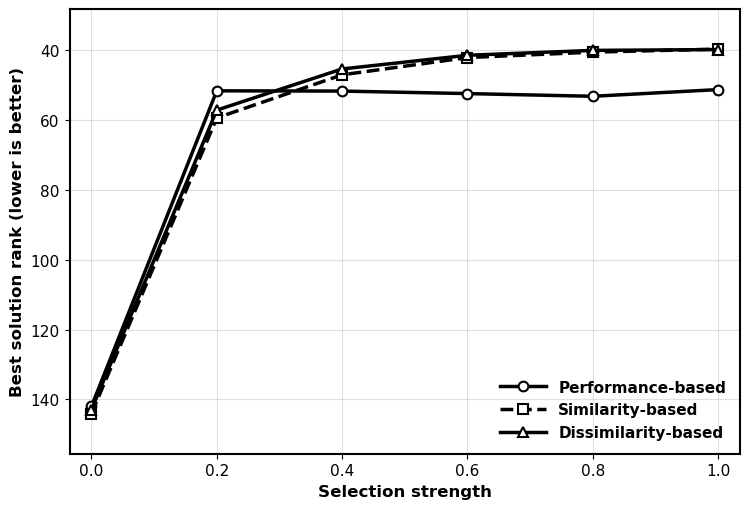

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Integrated_selection_figures/Pairwise_diversity_across_selection_strength.png


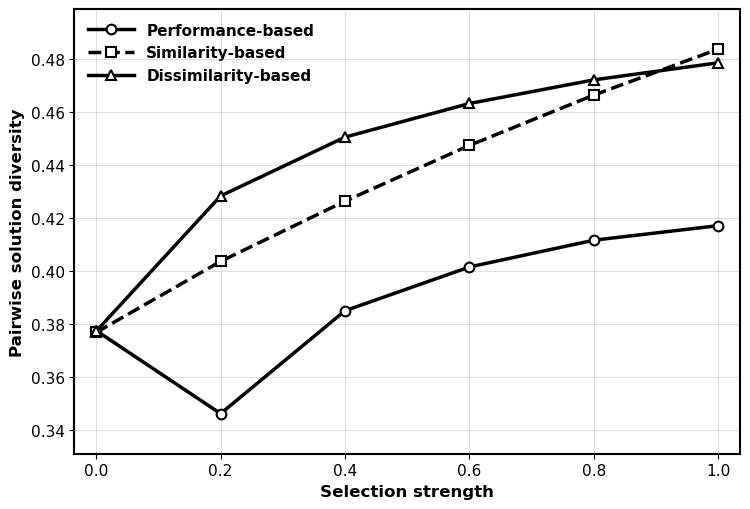

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Integrated_selection_figures/Adopted_solution_quality_across_selection_strength.png


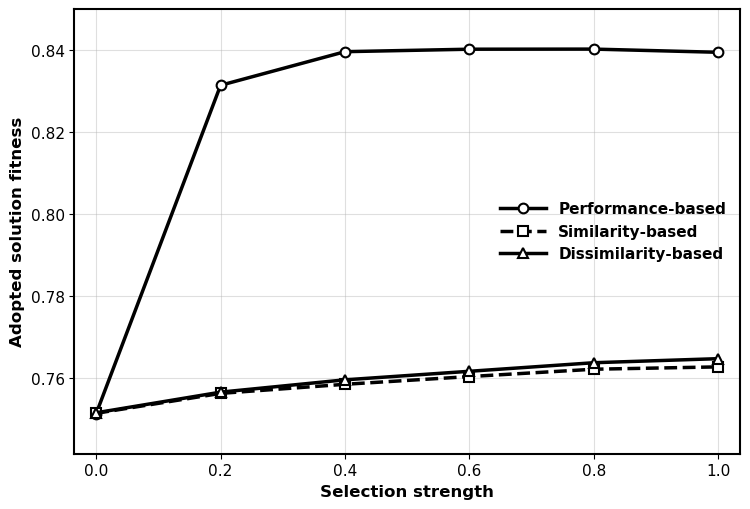

In [5]:
def plot_outcome(ax, dv, show_legend=True, panel_title=None):
    format_axis(ax)
    for rule, settings in selection_rules.items():
        ax.plot(
            x, means[rule][dv], label=rule,
            marker=settings['marker'], linestyle=settings['linestyle'],
            color='black', linewidth=2.5, markersize=7,
            markerfacecolor='white', markeredgecolor='black',
            markeredgewidth=1.5,
        )
    ax.set_xticks(x)
    ax.set_xlim(-0.035, 1.035)
    ax.margins(y=0.11)
    ax.set_xlabel('Selection strength', fontweight='bold', fontsize=12)
    ax.set_ylabel(outcomes[dv]['ylabel'], fontweight='bold', fontsize=12)
    if dv == 'breakthrough_rank':
        ax.invert_yaxis()
    if panel_title is not None:
        ax.set_title(panel_title, fontweight='bold', fontsize=12, pad=10)
    if show_legend:
        ax.legend(frameon=False, prop=legend_properties, loc='best', handlelength=3.0)
    return ax


def save_and_show(fig, filename):
    if save_figures:
        output = figure_folder / filename
        fig.savefig(output, dpi=300, bbox_inches='tight', transparent=True)
        print('Saved:', output)
    plt.show()


# Separate outcome figures (same filenames as original evaluator).
for dv, settings in outcomes.items():
    fig, ax = plt.subplots(figsize=(7.6, 5.2))
    plot_outcome(ax, dv)
    fig.tight_layout()
    save_and_show(fig, settings['filename'])

### Unified multi-panel figure

The default layout is a single row of three panels (breakthrough, dispersion, orientation). Enabling generative potential changes it to a 2 × 2 layout. The shared legend identifies rules consistently in all panels.

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Integrated_selection_figures/Integrated_selection.png


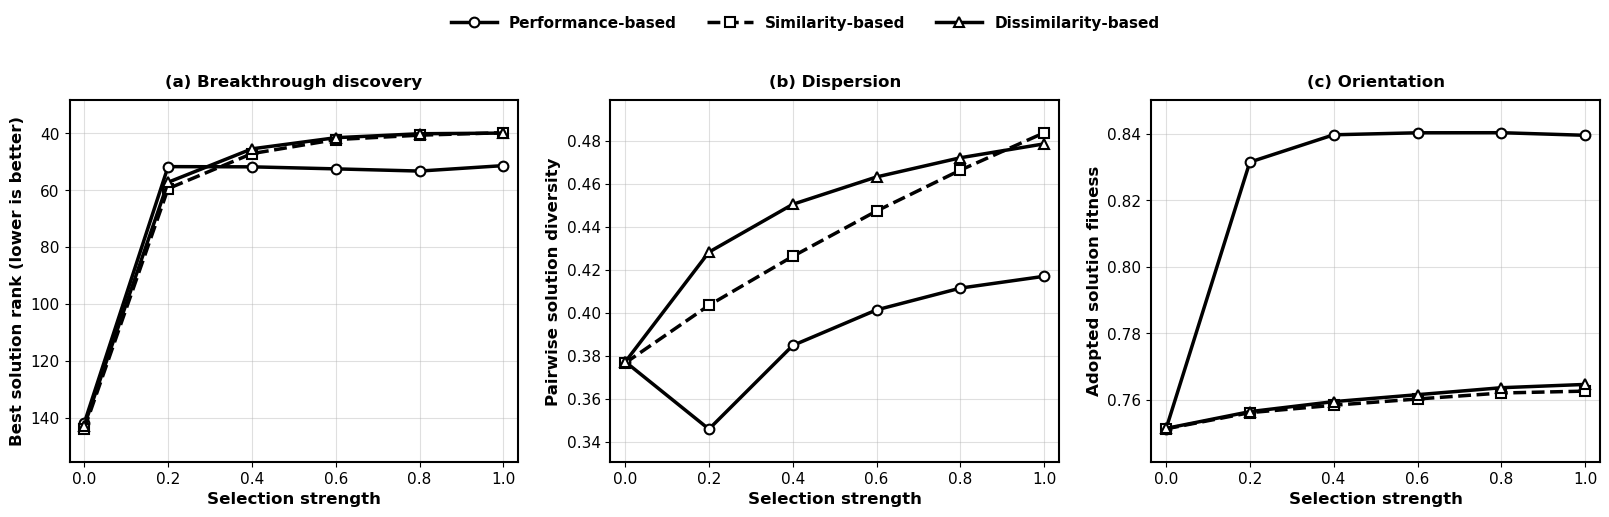

In [6]:
# Unified figure for manuscript use.
if include_generative_potential:
    fig, axes = plt.subplots(2, 2, figsize=(12.0, 9.0))
else:
    fig, axes = plt.subplots(1, 3, figsize=(16.2, 5.2))

for i, (ax, dv) in enumerate(zip(axes.flat, outcomes)):
    plot_outcome(ax, dv, show_legend=False,
                 panel_title=f'({chr(97 + i)}) {outcomes[dv]["title"]}')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False,
           prop=legend_properties, handlelength=3.0, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.89), w_pad=2.0, h_pad=2.0)
filename = ('Integrated_selection_with_generative_potential.png'
            if include_generative_potential else 'Integrated_selection.png')
save_and_show(fig, filename)